# Análise Exploratória de Dados de E-commerce

## Objetivo

Analisar os dados de produtos de um e-commerce utilizando Python,
Pandas, Matplotlib e Seaborn.

O projeto apresenta sete gráficos para compreender os preços,
as avaliações, as marcas e outras características dos produtos.

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar os dados
df = pd.read_csv('ecommerce_estatistica.csv')

# Verificar os dados
print("Quantidade de linhas e colunas:", df.shape)
print("\nColunas disponíveis:")
print(df.columns.tolist())
print("\nValores nulos:")
print(df.isnull().sum())

# Visualizar as primeiras linhas
df.head()

Quantidade de linhas e colunas: (295, 24)

Colunas disponíveis:
['Unnamed: 0', 'Título', 'Nota', 'N_Avaliações', 'Desconto', 'Marca', 'Material', 'Gênero', 'Temporada', 'Review1', 'Review2', 'Review3', 'Qtd_Vendidos', 'Preço', 'Nota_MinMax', 'N_Avaliações_MinMax', 'Desconto_MinMax', 'Preço_MinMax', 'Marca_Cod', 'Material_Cod', 'Temporada_Cod', 'Qtd_Vendidos_Cod', 'Marca_Freq', 'Material_Freq']

Valores nulos:
Unnamed: 0             0
Título                 0
Nota                   0
N_Avaliações           0
Desconto               0
Marca                  0
Material               0
Gênero                 0
Temporada              0
Review1                0
Review2                0
Review3                0
Qtd_Vendidos           0
Preço                  0
Nota_MinMax            0
N_Avaliações_MinMax    0
Desconto_MinMax        0
Preço_MinMax           0
Marca_Cod              0
Material_Cod           0
Temporada_Cod          0
Qtd_Vendidos_Cod       0
Marca_Freq             0
Material_Fre

,Unnamed: 0,Título,Nota,N_Avaliações,Desconto,Marca,Material,Gênero,Temporada,Review1,...,Nota_MinMax,N_Avaliações_MinMax,Desconto_MinMax,Preço_MinMax,Marca_Cod,Material_Cod,Temporada_Cod,Qtd_Vendidos_Cod,Marca_Freq,Material_Freq
0,1,Kit 10 Cuecas Boxer Lupo Cueca Box Algodão Mas...,4.5,3034.0,18.0,lupo,algodão,Masculino,outono/inverno,As cuecas são boas; porém você percebe na cost...,...,0.814815,0.334178,0.213115,0.378585,463,25,3,10000.0,0.042292,0.176444
1,2,Kit Com 10 Cuecas Boxer Algodão Sem Costura Zo...,4.7,5682.0,20.0,zorba,algodão,Masculino,não definido,O tecido é bom e são confortáveis. Só que a nu...,...,0.888889,0.625937,0.245902,0.322329,838,25,1,50000.0,0.009095,0.176444
2,3,Kit 10 Cuecas Boxer Mash Algodão Cotton Box Or...,4.6,1700.0,22.0,mash,algodão,Masculino,primavera/verão,"As cuecas são boas, porém meu marido usa g e p...",...,0.851852,0.187197,0.278689,0.372617,494,25,7,10000.0,0.010914,0.176444
3,4,Kit 3 Short Jeans Feminino Cintura Alta Barato...,4.4,507.0,9.0,menina linda,jean,Feminino,primavera/verão,Estou encantada com essas peças!.\nOs shorts s...,...,0.777778,0.055751,0.065574,0.201767,509,74,7,1000.0,0.010005,0.025466
4,5,Blusa + Calça Térmica Treino Futebol Criança I...,4.7,58.0,5.0,roupa zero grau,termico unissex,Sem gênero infantil,outono/inverno,"Produto ótimo , mesmo após várias lavagens não...",...,0.888889,0.006280,0.000000,0.114508,669,166,3,100.0,0.002274,0.000910


## 1. Histograma — Distribuição dos Preços

O objetivo deste gráfico é identificar as faixas de preço
mais frequentes entre os produtos do e-commerce.

A maioria dos produtos apresenta preços entre 40 e 200 reais.
Os produtos acima de 250 reais são menos frequentes,
indicando uma menor concentração nas faixas de preços mais elevadas.

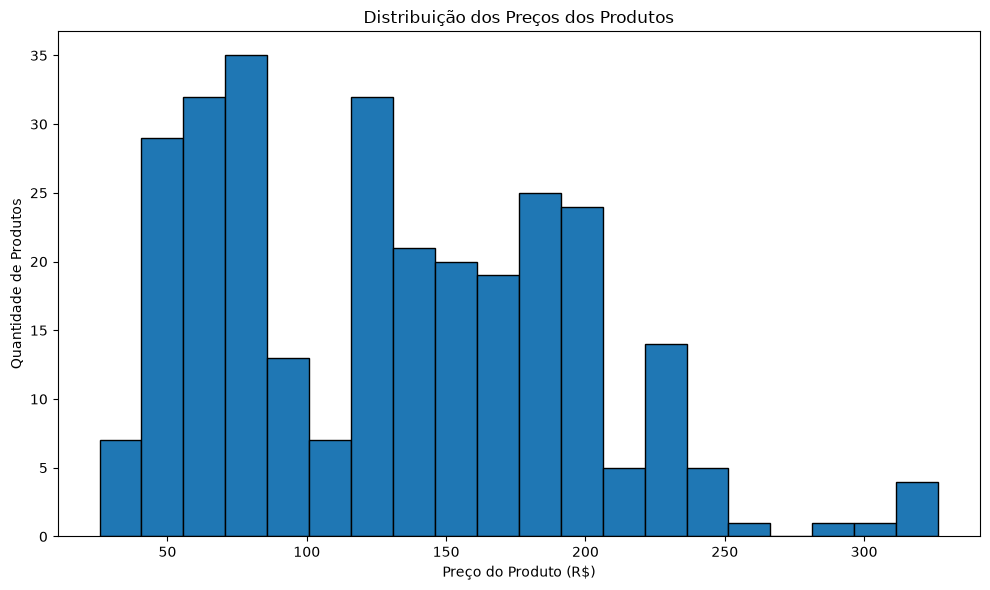

In [25]:
plt.figure(figsize=(10,6))
plt.hist(df['Preço'].dropna(), bins=20, edgecolor='black')
plt.title('Distribuição dos Preços dos Produtos')
plt.xlabel('Preço do Produto (R$)')
plt.ylabel('Quantidade de Produtos')
plt.tight_layout()
plt.show()

### 2. Gráfico de dispersão
A relação entre preço e número de avaliações não apresenta uma
tendência linear forte. Existem produtos com muitas avaliações
em diferentes faixas de preço.

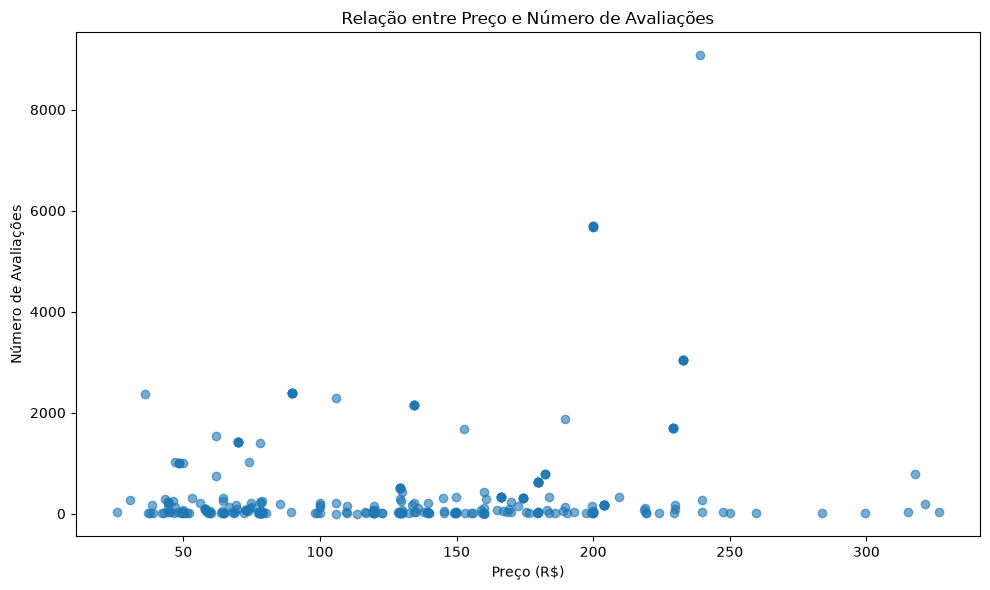

In [26]:
plt.figure(figsize=(10,6))
plt.scatter(df['Preço'], df['N_Avaliações'], alpha=0.6)
plt.title('Relação entre Preço e Número de Avaliações')
plt.xlabel('Preço (R$)')
plt.ylabel('Número de Avaliações')
plt.tight_layout()
plt.show()

### 3. Mapa de calor
A correlação mais forte encontrada foi entre número de avaliações
e quantidade vendida codificada, com coeficiente de aproximadamente
0,91. As demais correlações analisadas foram consideravelmente menores

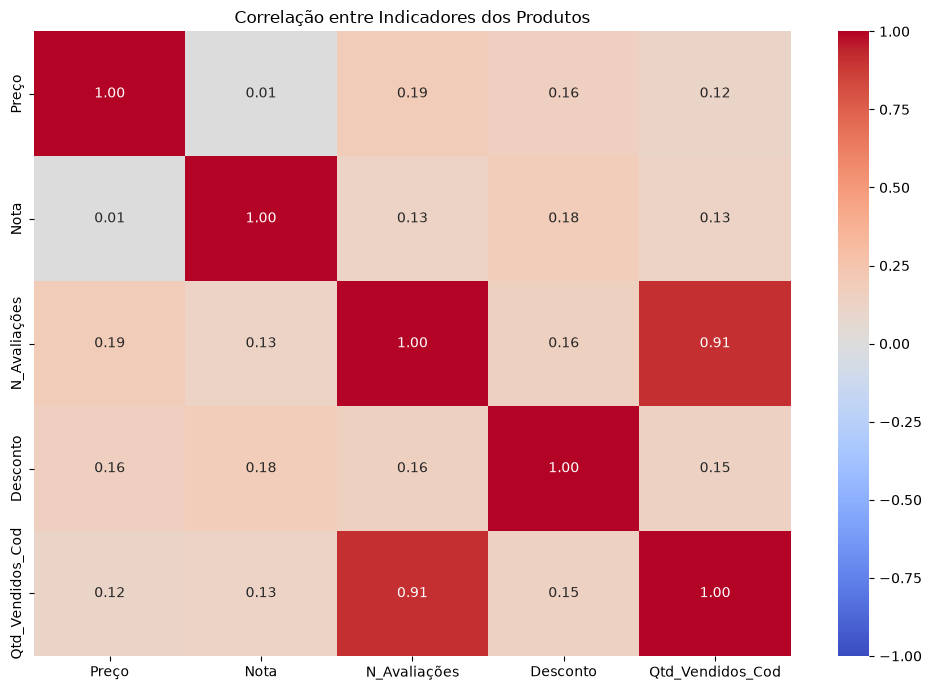

In [32]:
colunas = ['Preço','Nota','N_Avaliações','Desconto','Qtd_Vendidos_Cod']
correlacao = df[colunas].corr()
plt.figure(figsize=(10,7))
sns.heatmap(
    correlacao,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    center=0
)
plt.title('Correlação entre Indicadores dos Produtos')
plt.tight_layout()
plt.show()

### 4. Gráfico de barras
A marca Lupo possui a maior quantidade de produtos cadastrados
na base analisada, com 40 registros. Outras marcas apresentam
participações menores no catálogo.

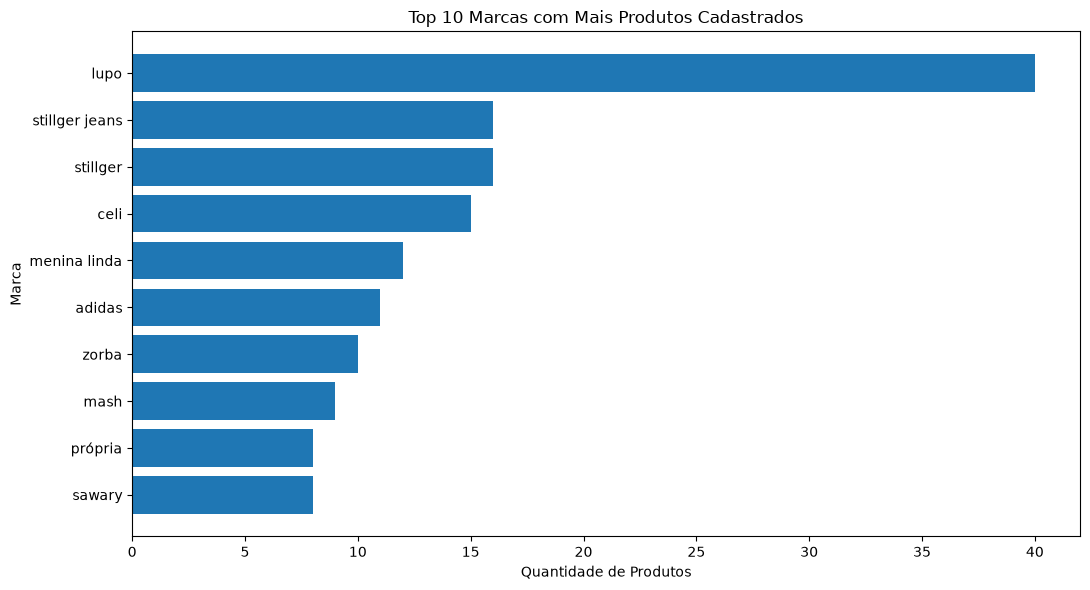

In [28]:
top_marcas = df['Marca'].value_counts().head(10)
plt.figure(figsize=(11,6))
plt.barh(top_marcas.index, top_marcas.values)
plt.title('Top 10 Marcas com Mais Produtos Cadastrados')
plt.xlabel('Quantidade de Produtos')
plt.ylabel('Marca')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 5. Gráfico de pizza
A categoria primavera/verão representa aproximadamente 45,1%
dos produtos, seguida por outono/inverno, com 28,1%.

Aproximadamente 21% dos produtos não possuem temporada definida,
o que indica uma oportunidade de melhoria na qualidade dos dados.

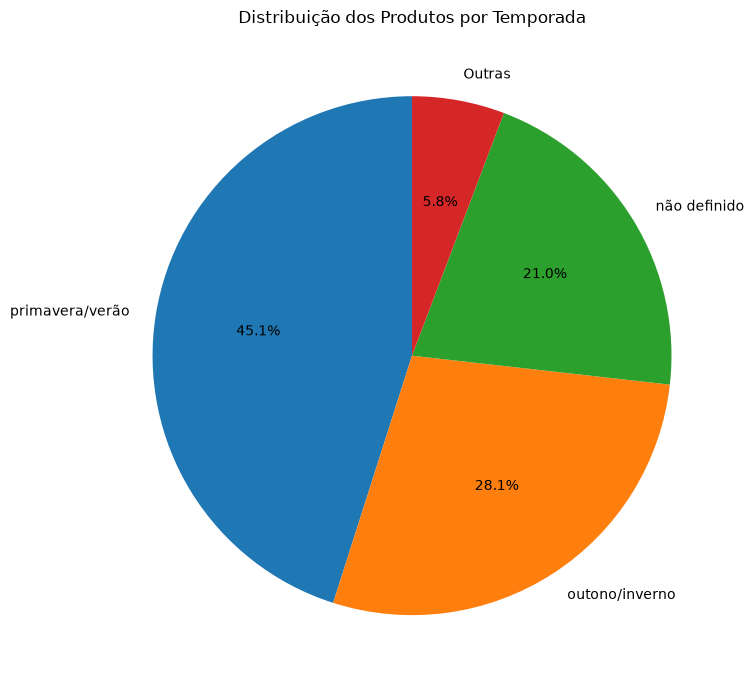

In [29]:
temporadas = df['Temporada'].value_counts()
principais = temporadas.head(3).copy()
principais['Outras'] = temporadas.iloc[3:].sum()
plt.figure(figsize=(9, 7))
plt.pie(principais,labels=principais.index,autopct='%1.1f%%',startangle=90)
plt.title('Distribuição dos Produtos por Temporada')
plt.tight_layout()
plt.show()

## 6. Gráfico de densidade

Os preços apresentam maior concentração nas faixas mais baixas e intermediárias, com um pico próximo de 70 reais e outra concentração entre 130 e 180 reais.

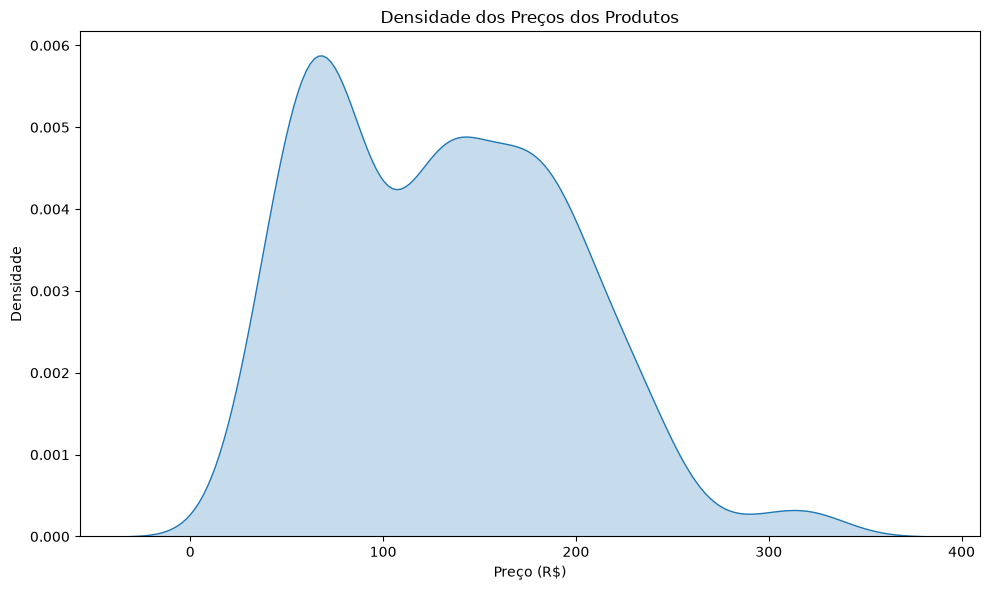

In [30]:
plt.figure(figsize=(10,6))
sns.kdeplot(x='Preço', data=df, fill=True)
plt.title('Densidade dos Preços dos Produtos')
plt.xlabel('Preço (R$)')
plt.ylabel('Densidade')
plt.tight_layout()
plt.show()

### 7. Gráfico de regressão
Existe uma tendência positiva entre o número de avaliações
e a quantidade vendida codificada.

Entretanto, alguns valores extremos influenciam a linha de regressão.
Além disso, os valores de vendas representam faixas convertidas
em números, o que exige cuidado na interpretação.

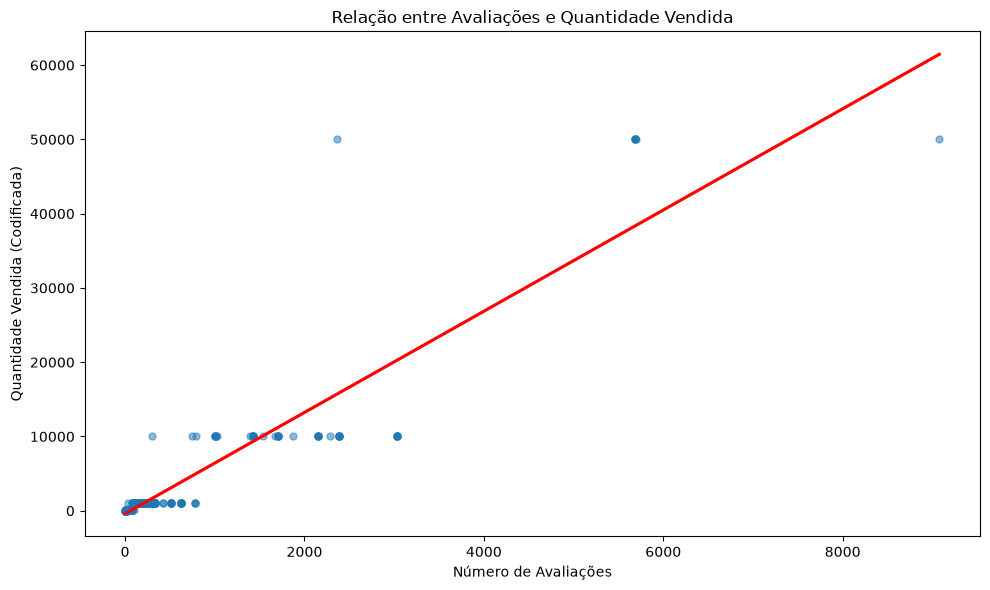

In [31]:
plt.figure(figsize=(10, 6))

sns.regplot( data=df,
    x='N_Avaliações',
    y='Qtd_Vendidos_Cod',
    ci=None,
    scatter_kws={'alpha': 0.5, 's': 25},
    line_kws={'color': 'red'}
)
plt.title('Relação entre Avaliações e Quantidade Vendida')
plt.xlabel('Número de Avaliações')
plt.ylabel('Quantidade Vendida (Codificada)')
plt.tight_layout()
plt.show()

## Conclusão

A análise permitiu compreender melhor a distribuição de preços,
as marcas mais presentes no catálogo e as relações entre
avaliações, preços e quantidade vendida.

O resultado mais relevante foi a forte associação entre o número
de avaliações e a quantidade vendida codificada.

Também foram identificadas oportunidades de melhoria na qualidade
dos dados, principalmente no preenchimento e padronização da
coluna Temporada.

Os gráficos ajudam a compreender o catálogo e podem contribuir
para análises comerciais futuras. Entretanto, os resultados
representam apenas os produtos presentes na base analisada.